Dataset loaded successfully!
Price       Date         Close          High           Low          Open  \
0     2021-10-06  17646.000000  17884.599609  17613.150391  17861.500000   
1     2021-10-07  17790.349609  17857.550781  17763.800781  17810.550781   
2     2021-10-08  17895.199219  17941.849609  17840.349609  17886.849609   
3     2021-10-11  17945.949219  18041.949219  17839.099609  17867.550781   
4     2021-10-12  17991.949219  18008.650391  17864.949219  17915.800781   

Price  Volume  
0      395800  
1      419900  
2      324100  
3      375800  
4      355600  

Dataset Shape: (1235, 6)

Missing Values:
Price
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

Target Distribution:
Target
1    644
0    589
Name: count, dtype: int64

Training Data: (986, 10)
Testing Data: (247, 10)

 Decision Tree Classifier
---------------------------
Accuracy : 0.5546558704453441
Precision: 0.56
Recall   : 0.45901639344262296
F1 Score : 0.5045045045045045

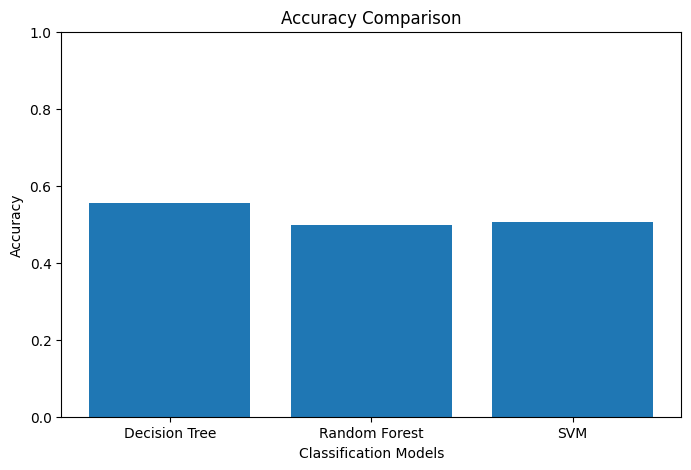

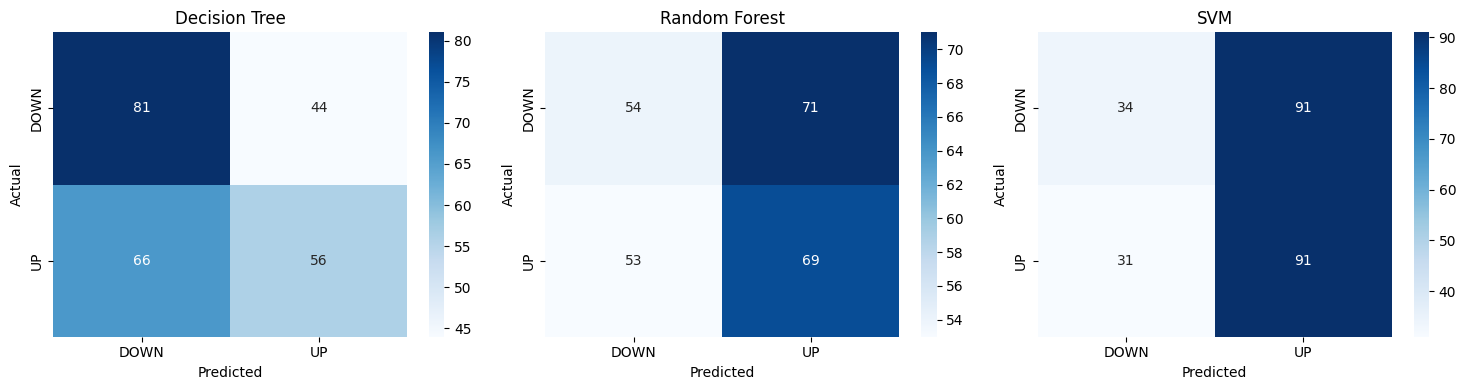


Actual vs Predicted:
    Actual  Decision Tree  Random Forest  SVM
0        1              1              0    1
1        1              1              1    1
2        0              1              1    1
3        1              1              0    1
4        1              1              1    1
5        0              1              0    1
6        0              0              0    1
7        1              0              0    1
8        1              1              0    1
9        1              1              1    0
10       1              1              0    0
11       1              0              1    1
12       1              0              1    0
13       0              1              1    1
14       1              0              0    1

NEXT TRADING DAY CLASSIFICATION
Decision Tree : UP
Random Forest : DOWN
SVM           : UP


In [1]:

# ==========================================
# STOCK MARKET CLASSIFICATION
# Decision Tree vs Random Forest vs SVM
# Dataset: NIFTY 50
# ==========================================

# 1. Install library
!pip -q install yfinance

# 2. Import libraries
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ==========================================
# 3. Download NIFTY 50 dataset
# ==========================================

df = yf.download(
    "^NSEI",
    period="5y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df.reset_index()
df = df.dropna()

print("Dataset loaded successfully!")
print(df.head())

print("\nDataset Shape:", df.shape)

# ==========================================
# 4. Data preprocessing
# ==========================================

print("\nMissing Values:")
print(df.isnull().sum())

# ==========================================
# 5. Feature engineering
# ==========================================

# Today's market information
df["Previous_Close"] = df["Close"].shift(1)
df["Previous_Open"] = df["Open"].shift(1)
df["Previous_High"] = df["High"].shift(1)
df["Previous_Low"] = df["Low"].shift(1)
df["Previous_Volume"] = df["Volume"].shift(1)

# Next trading day's closing price
df["Next_Close"] = df["Close"].shift(-1)

# Classification target
# 1 = UP
# 0 = DOWN or unchanged

df["Target"] = (
    df["Next_Close"] > df["Close"]
).astype(int)

df = df.dropna().reset_index(drop=True)

# ==========================================
# 6. Select features and target
# ==========================================

features = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Previous_Close",
    "Previous_Open",
    "Previous_High",
    "Previous_Low",
    "Previous_Volume"
]

X = df[features]
y = df["Target"]

print("\nTarget Distribution:")
print(y.value_counts())

# ==========================================
# 7. Train-test split
# ==========================================

# Maintain chronological order
split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)

# ==========================================
# 8. Decision Tree Classifier
# ==========================================

dt_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

# ==========================================
# 9. Random Forest Classifier
# ==========================================

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

# ==========================================
# 10. SVM Classifier
# ==========================================

svm_model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    )
)

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

# ==========================================
# 11. Evaluation function
# ==========================================

def evaluate_model(name, actual, predicted):

    accuracy = accuracy_score(actual, predicted)

    precision = precision_score(
        actual, predicted, zero_division=0
    )

    recall = recall_score(
        actual, predicted, zero_division=0
    )

    f1 = f1_score(
        actual, predicted, zero_division=0
    )

    print("\n", name)
    print("---------------------------")
    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1 Score :", f1)

    print("\nClassification Report:")
    print(classification_report(
        actual,
        predicted,
        labels=[0, 1],
        target_names=["DOWN", "UP"],
        zero_division=0
    ))

    return accuracy, precision, recall, f1

# ==========================================
# 12. Evaluate all three models
# ==========================================

dt_results = evaluate_model(
    "Decision Tree Classifier",
    y_test,
    dt_pred
)

rf_results = evaluate_model(
    "Random Forest Classifier",
    y_test,
    rf_pred
)

svm_results = evaluate_model(
    "SVM Classifier",
    y_test,
    svm_pred
)

# ==========================================
# 13. Model comparison table
# ==========================================

comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "SVM"
    ],

    "Accuracy": [
        dt_results[0],
        rf_results[0],
        svm_results[0]
    ],

    "Precision": [
        dt_results[1],
        rf_results[1],
        svm_results[1]
    ],

    "Recall": [
        dt_results[2],
        rf_results[2],
        svm_results[2]
    ],

    "F1 Score": [
        dt_results[3],
        rf_results[3],
        svm_results[3]
    ]
})

print("\n================================")
print("CLASSIFICATION MODEL COMPARISON")
print("================================")

print(comparison.round(4))

# ==========================================
# 14. Accuracy comparison graph
# ==========================================

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Accuracy"]
)

plt.title("Accuracy Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.show()

# ==========================================
# 15. Confusion matrices
# ==========================================

models = {
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "SVM": svm_pred
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, predictions) in zip(axes, models.items()):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["DOWN", "UP"],
        yticklabels=["DOWN", "UP"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

# ==========================================
# 16. Compare predictions
# ==========================================

results = pd.DataFrame({
    "Actual": y_test.values,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "SVM": svm_pred
})

print("\nActual vs Predicted:")
print(results.head(15))

# ==========================================
# 17. Predict next trading day direction
# ==========================================

latest_data = X.iloc[[-1]]

dt_next = dt_model.predict(latest_data)[0]
rf_next = rf_model.predict(latest_data)[0]
svm_next = svm_model.predict(latest_data)[0]

def direction(value):
    return "UP" if value == 1 else "DOWN"

print("\n================================")
print("NEXT TRADING DAY CLASSIFICATION")
print("================================")

print("Decision Tree :", direction(dt_next))
print("Random Forest :", direction(rf_next))
print("SVM           :", direction(svm_next))
